# 02 — Exploratory analysis

A first look at the price series before any model.

- **Input:** `data/processed/mgp_prices_hourly_2021_2025q3.parquet`
- **Output:** plots only
- **Key findings:** three gas regimes (pre-crisis, 2021/22 crisis, post-crisis); strong daily and weekly seasonality; hours at zero price; **market splitting** in 33.6% of hours, mostly on the North / rest-of-Italy border (NORD − SUD spread +13.7 €/MWh at 11:00, −5.4 at 20:00).

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PROCESSED = Path.cwd().parent / "data" / "processed"

# Start from the file, not from a live kernel: this cell is the proof that
# 01_ingestion produced something self-contained.
prices = pd.read_parquet(PROCESSED / "mgp_prices_hourly_2021_2025q3.parquet")

# Same invariants as at the end of ingestion. If a check that passed there
# fails here, the parquet round-trip lost something.
assert len(prices) == 41615
assert prices["ts_utc"].is_unique
assert (prices["ts_utc"].diff().dropna() == pd.Timedelta("1h")).all()

print(prices.shape)
print(prices.dtypes[["ts_utc", "ts_local", "price_source", "national_price"]])

(41615, 26)
ts_utc                    datetime64[us, UTC]
ts_local          datetime64[us, Europe/Rome]
price_source                              str
national_price                        float64
dtype: object


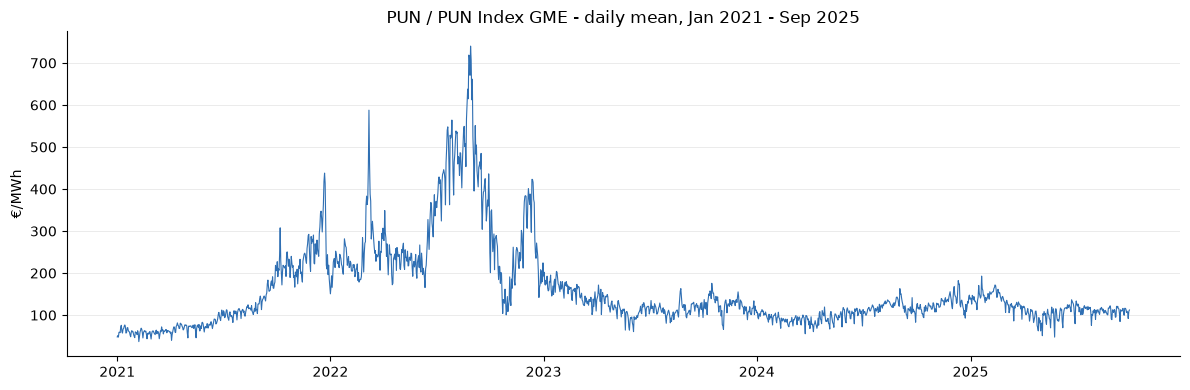

       day      price
2022-08-29 740.091314
2022-08-26 718.712219
2022-08-27 713.691593
2022-08-30 706.416130
2022-08-28 670.730653

           mean  median    std   min    max
ts_local                                   
2021      125.5    94.5   81.1   3.0  533.2
2022      304.0   264.3  133.1  10.0  870.0
2023      127.2   122.0   35.6   2.5  295.0
2024      108.5   105.8   29.7   0.1  275.1
2025      116.4   115.8   32.0   0.0  289.0


In [4]:
import matplotlib.pyplot as plt

# Daily mean on the LOCAL calendar date: a trading day is an Italian day,
# not a UTC one. (Aggregating on the UTC date would shift every daily mean
# by one or two hours and blur the day/night boundary.)
daily = (
    prices.assign(day=prices["ts_local"].dt.normalize().dt.tz_localize(None))
          .groupby("day", as_index=False)
          .agg(price=("national_price", "mean"))
)

fig, ax = plt.subplots(figsize=(12, 4))

# One series -> one hue, no legend needed: the title names it.
ax.plot(daily["day"], daily["price"], lw=0.8, color="#2f6fb3")

ax.set_title("PUN / PUN Index GME - daily mean, Jan 2021 - Sep 2025")
ax.set_ylabel("€/MWh")
ax.set_xlabel("")

# Recessive grid and axes: the data is the ink, the scaffolding is not.
ax.grid(axis="y", lw=0.5, alpha=0.35)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)

fig.tight_layout()
plt.show()

# The numbers behind the picture - never read a chart without them.
print(daily.nlargest(5, "price").to_string(index=False))
print()
print(prices.groupby(prices["ts_local"].dt.year)["national_price"]
            .agg(["mean", "median", "std", "min", "max"]).round(1))

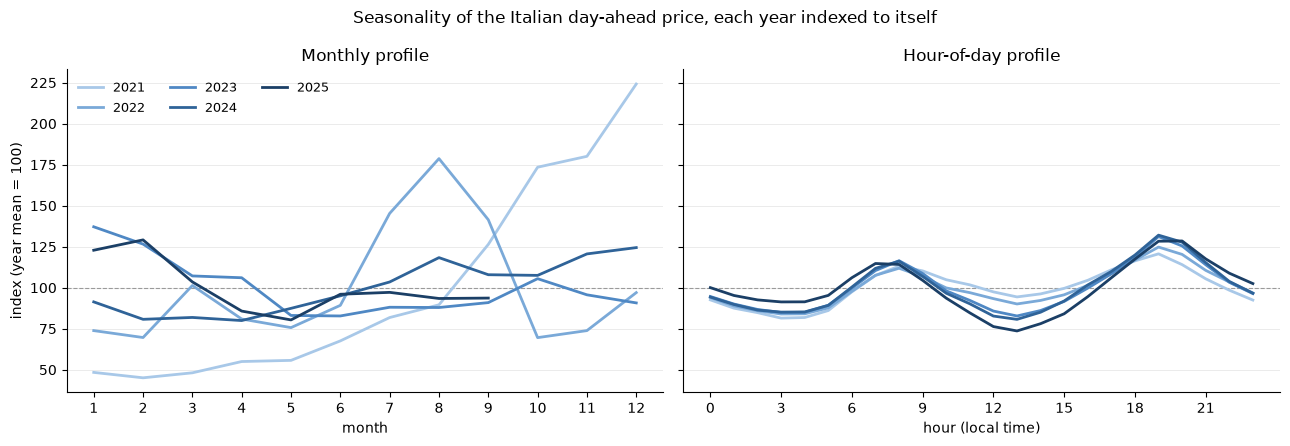

year    2021   2022   2023   2024   2025
month                                   
1       48.4   73.9  137.1   91.4  122.9
2       45.1   69.6  126.6   80.7  129.2
3       48.1  101.4  107.2   81.9  103.5
4       55.0   80.9  106.1   80.0   85.8
5       55.7   75.7   83.1   87.4   80.4
6       67.6   89.3   82.8   95.1   96.0
7       81.8  145.3   88.1  103.5   97.2
8       89.6  178.7   87.9  118.3   93.4
9      126.4  141.4   90.9  107.9   93.7
10     173.5   69.6  105.5  107.5    NaN
11     180.1   73.9   95.7  120.6    NaN
12     224.2   97.0   90.7  124.5    NaN

year   2021   2022   2023   2024   2025
hour                                   
0      92.6   94.1   94.6   94.3  100.1
1      87.5   88.9   90.1   89.8   95.3
2      84.8   86.0   86.8   86.4   92.6
3      81.5   84.0   84.9   85.2   91.3
4      81.8   84.1   85.0   85.2   91.4
5      86.1   87.7   89.3   89.3   95.3
6      97.5   97.8   99.7  100.4  106.1
7     107.5  107.6  110.5  111.8  114.8
8     113.1  111.9  116.5

In [3]:
df = prices.copy()
df["year"]  = df["ts_local"].dt.year
df["month"] = df["ts_local"].dt.month
df["hour"]  = df["ts_local"].dt.hour

# Index each year to its own annual mean = 100. Seasonality is a question
# about SHAPE, not level: without this the 2022 crisis dominates the plot
# and you cannot tell whether August is expensive every year or only once.
df["indexed"] = 100 * df["national_price"] / df.groupby("year")["national_price"].transform("mean")

monthly = df.pivot_table(index="month", columns="year", values="indexed", aggfunc="mean")
hourly  = df.pivot_table(index="hour",  columns="year", values="indexed", aggfunc="mean")

# Years are ORDERED, not categories -> one hue, light to dark, so the eye
# reads chronology without consulting the legend.
RAMP = {2021: "#a8c8e8", 2022: "#7aa9d8", 2023: "#4f88c4",
        2024: "#2f6398", 2025: "#1b3f66"}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)

for y in monthly.columns:
    axes[0].plot(monthly.index, monthly[y], color=RAMP[y], lw=2, label=str(y))
    axes[1].plot(hourly.index,  hourly[y],  color=RAMP[y], lw=2, label=str(y))

for ax, title, xlabel in [(axes[0], "Monthly profile", "month"),
                          (axes[1], "Hour-of-day profile", "hour (local time)")]:
    # Reference line: 100 = that year's own average price.
    ax.axhline(100, color="#9a9a9a", lw=0.8, ls="--", zorder=1)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", lw=0.5, alpha=0.35)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

axes[0].set_ylabel("index (year mean = 100)")
axes[0].set_xticks(range(1, 13))
axes[1].set_xticks(range(0, 24, 3))
axes[0].legend(frameon=False, ncol=3, fontsize=9)

fig.suptitle("Seasonality of the Italian day-ahead price, each year indexed to itself")
fig.tight_layout()
plt.show()

print(monthly.round(1))
print()
print(hourly.round(1))

In [8]:
# 02_eda addition: how often does the Italian market actually split?
# An hour is "coupled" when all zones clear at the same price, i.e. no
# interconnection was saturated. Adjust the column names to whatever they
# are called in your parquet.
ZONE_COLS = ["NORD", "CNOR", "CSUD", "SUD", "CALA", "SICI", "SARD"]

prices = pd.read_parquet("../data/processed/mgp_prices_hourly_2021_2025q3.parquet")
zonal = prices[ZONE_COLS]

# Tolerance instead of exact equality: published prices are rounded.
is_split = (zonal.max(axis=1) - zonal.min(axis=1)) > 0.01
print(f"split hours: {is_split.sum()} / {len(is_split)} ({is_split.mean():.1%})")

print("\nshare of split hours by year:")
print(is_split.groupby(prices["ts_utc"].dt.year).mean().round(3).to_string())

# Where the spread is widest: the structural congestion of the Italian grid.
print("\nmean price by zone:")
print(zonal.mean().round(2).sort_values().to_string())

split hours: 13992 / 41615 (33.6%)

share of split hours by year:
ts_utc
2020    0.000
2021    0.461
2022    0.332
2023    0.263
2024    0.319
2025    0.297

mean price by zone:
SARD    152.47
CALA    155.49
SUD     155.97
CSUD    157.51
SICI    158.01
NORD    158.99
CNOR    159.75


In [9]:
# 02_eda: the zonal structure is conditional - it does not show up in the
# pooled mean. Look at it by year and by hour of day instead.
ROME = "Europe/Rome"

# Always group on LOCAL time: grouping on UTC puts the first hour of 2021
# (23:00 UTC of 31 Dec 2020) into the wrong year.
local_ts = prices["ts_utc"].dt.tz_convert(ROME)

print("split share by local year:")
print(is_split.groupby(local_ts.dt.year).mean().round(3).to_string())

# 1) Mean price by zone and year: the 2022 gas crisis adds a huge common
# component that hides the differences between zones.
print("\nmean price by zone and local year:")
print(prices.groupby(local_ts.dt.year)[ZONE_COLS].mean().round(1).to_string())

# 2) NORD - SUD spread by hour of day. Averaged over all hours (it is zero
# when the market is coupled), so this is the average basis a northern
# position would carry against a southern one.
spread_nord_sud = prices["NORD"] - prices["SUD"]
print("\nmean NORD - SUD spread by hour of day:")
print(spread_nord_sud.groupby(local_ts.dt.hour).mean().round(2).to_string())

# 3) Which zone is the expensive one when the market does split? Restricted
# to split hours, otherwise ties make idxmax meaningless.
print("\nmost expensive zone, share of split hours:")
print(prices.loc[is_split, ZONE_COLS].idxmax(axis=1).value_counts(normalize=True).round(3).to_string())
print("\ncheapest zone, share of split hours:")
print(prices.loc[is_split, ZONE_COLS].idxmin(axis=1).value_counts(normalize=True).round(3).to_string())

split share by local year:
ts_utc
2021    0.461
2022    0.332
2023    0.263
2024    0.319
2025    0.297

mean price by zone and local year:
         NORD   CNOR   CSUD    SUD   CALA   SICI   SARD
ts_utc                                                 
2021    125.2  125.4  125.3  123.6  123.3  129.0  123.6
2022    307.8  307.6  298.9  295.8  294.2  295.1  287.0
2023    127.8  128.5  126.4  125.1  124.7  126.1  123.2
2024    107.4  109.4  109.8  109.1  109.1  112.2  106.2
2025    116.1  117.2  117.0  116.4  116.3  117.6  112.4

mean NORD - SUD spread by hour of day:
ts_utc
0     -1.31
1     -0.79
2     -0.16
3      0.00
4     -0.18
5     -0.27
6      0.05
7      1.22
8      4.79
9      7.86
10    11.33
11    13.72
12    11.49
13    12.17
14    11.38
15     8.14
16     4.24
17     1.91
18     0.52
19    -2.99
20    -5.44
21    -3.70
22    -1.89
23     0.33

most expensive zone, share of split hours:
NORD    0.478
SICI    0.276
CNOR    0.110
CSUD    0.094
CALA    0.042
SARD    0.000

chea